# Search: Solving a Maze Using a Goal-based Agent

Student Name: Phan Lê Ngọc Như Ý (MSSV: 3124720079) - Nhóm: Phan Lê Ngọc Như Ý, Bùi Quyền Kiệt, Bùi Anh Đức, Phạm Thái Duy Khang

I have used the following AI tools: ChatGPT, GitHub Copilot

I understand that my submission needs to be my own work: PLNNY

## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement the search algorithm BFS for planning paths through mazes.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file. 


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze. 

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent 
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.** 
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state. 
* **Discrete** means that we have a **finite set of states.** The maze has a finite set 
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The 
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible. 

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [1]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "large_maze.txt", "open_maze.txt", "empty_maze.txt"]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [2]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`. 

In [3]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

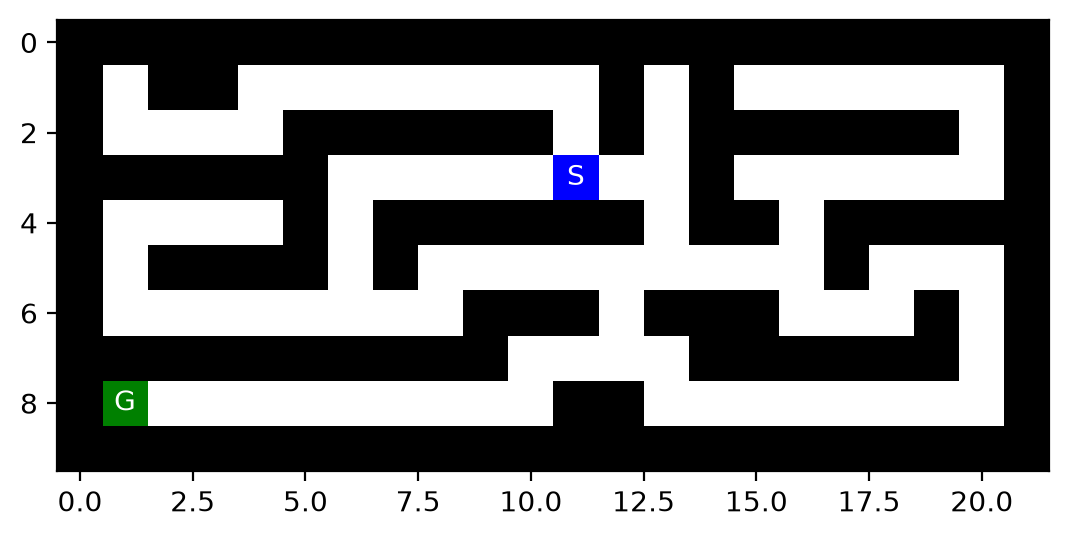

In [4]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [5]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [6]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x, y).

        Para

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step. 

In [7]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0
        
        # check if plan is completed
        if self.progress >= len(self.plan):        
            raise Exception("Completed Plan. No more planned actions")
        
        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [8]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['N', 'N', 'N', 'N', 'N', 'N', 'W', 'S', 'W', 'S']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [9]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: E
Following plan... step 1: E
Following plan... step 2: W
Following plan... step 3: W
Following plan... step 4: E
Following plan... step 5: W
Following plan... step 6: W
Following plan... step 7: E
Following plan... step 8: W
Following plan... step 9: N
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python. 
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [10]:
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)    # the state; positions are (row,col)
        self.parent = parent     # reference to parent node. None means root node.
        self.action = action     # action used in the transition function (root node has None)
        self.cost = cost         # for uniform cost this is the depth. It is also g(n) for A* search

    def __str__(self):
        return f"Node - pos = {self.pos}; action = {self.action}; cost = {self.cost}"
    
    def get_path_from_root(self):
        """returns nodes on the path from the root to the current node."""
        node = self
        path = [node]
    
        while not node.parent is None:
            node = node.parent
            path.append(node)
        
        path.reverse()
        
        return(path)

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithm for solving different mazes:
    - Breadth-first search (BFS)

2. Run each of the above algorithms on the 
    - [small maze](small_maze.txt), 
    - [large maze](large_maze.txt), 
    - [open maze](open_maze.txt), and
    - [empty maze](empty_maze.txt).

3. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [2 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate. 

*Note:* You can switch the next block from code to Markdown and use formatting.

### 1. Định nghĩa bài toán tìm kiếm (Problem Formulation)

Bài toán tìm đường đi trong mê cung được mô hình hóa dưới dạng một bài toán tìm kiếm đơn tác tử (single-agent), tất định (deterministic), rời rạc (discrete) và quan sát toàn phần (fully observable):

* **Không gian trạng thái ($S$):** 
  Không gian trạng thái bao gồm tập hợp tất cả các tọa độ hợp lệ $(r, c)$ trên lưới mê cung có kích thước $R \times C$. Một trạng thái đại diện cho vị trí hiện tại $(row, col)$ của tác tử. Các trạng thái bị giới hạn ở các ô có thể đi qua (ô không phải tường):
  $$S = \{(r, c) \mid 0 \le r < R,\; 0 \le c < C,\; \text{maze}[r, c] \ne \text{'X'}\}$$
  Các ô trống `' '`, ô xuất phát `'S'` và ô đích `'G'` là các trạng thái hợp lệ; các ô tường `'X'` là vật cản và không thể đi vào.

* **Trạng thái ban đầu ($s_0$):** 
  Vị trí xuất phát của tác tử trong mê cung, được xác định bởi tọa độ của ký tự `'S'`:
  $$s_0 = (r_{\text{start}}, c_{\text{start}}) = \text{find\_pos}(\text{maze}, \text{'S'})$$

* **Tập hành động ($A(s)$):** 
  Từ một trạng thái $s = (r, c)$, tác tử có thể di chuyển một ô theo 4 hướng chính: Bắc (North), Đông (East), Nam (South), Tây (West):
  $$A(s) = \{a \in \{\text{'N'}, \text{'E'}, \text{'S'}, \text{'W'}\} \mid \text{Result}(s, a) \in S\}$$
  Một hành động được coi là hợp lệ khi và chỉ khi ô kế tiếp nằm trong phạm vi mê cung và không phải là tường (`'X'`).

* **Mô hình chuyển trạng thái ($\text{Result}(s, a)$):** 
  Hàm tất định xác định vị trí tiếp theo khi thực hiện hành động $a$ từ trạng thái $s = (r, c)$:
  $$\text{Result}((r, c), a) = \begin{cases} 
  (r - 1, c) & \text{nếu } a = \text{'N'} \\
  (r, c + 1) & \text{nếu } a = \text{'E'} \\
  (r + 1, c) & \text{nếu } a = \text{'S'} \\
  (r, c - 1) & \text{nếu } a = \text{'W'}
  \end{cases}$$

* **Trạng thái đích ($G$ / Kiểm tra đích):** 
  Trạng thái đích là vị trí được đánh dấu bởi ký tự `'G'`:
  $$s_g = (r_{\text{goal}}, c_{\text{goal}}) = \text{find\_pos}(\text{maze}, \text{'G'})$$
  Hàm kiểm tra đích $\text{Is-Goal}(s)$ trả về `True` nếu $s = s_g$ (hoặc $\text{maze}[s] == \text{'G'}$), và trả về `False` trong các trường hợp còn lại.

* **Chi phí đường đi ($c(s, a, s')$):** 
  Mỗi bước di chuyển hợp lệ có chi phí đơn vị bằng 1:
  $$c(s, a, s') = 1, \quad \forall s, s' \in S,\; a \in A(s)$$
  Tổng chi phí của một kế hoạch hành động $(a_1, a_2, \dots, a_k)$ chính là tổng số bước đi thực tế từ $s_0$ đến $G$:
  $$\text{Cost} = \sum_{i=1}^k c(s_{i-1}, a_i, s_i) = k$$


Give some estimates for the problem size:

* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

### 2. Ước lượng kích thước không gian bài toán ($d, m, b$)

* **$d$ — Độ sâu của lời giải tối ưu:**
  * **Định nghĩa:** Số bước di chuyển tối thiểu để đi từ trạng thái bắt đầu $s_0$ đến trạng thái đích $G$ theo đường đi ngắn nhất.
  * **Cách xác định:** Chạy thuật toán Tìm kiếm theo chiều rộng (BFS) hoặc thuật toán Dijkstra. Vì mọi hành động đều có chi phí đơn vị bằng nhau ($c=1$), BFS được đảm bảo về mặt toán học sẽ duyệt các trạng thái theo thứ tự độ sâu không giảm và luôn trả về lời giải có độ sâu tối ưu $d$.
  * **Giá trị cụ thể trên 4 mê cung thử nghiệm:**
    * `small_maze`: $d = 19$
    * `large_maze`: $d = 210$
    * `open_maze`: $d = 54$
    * `empty_maze`: $d = 14$

* **$m$ — Độ sâu tối đa của cây tìm kiếm:**
  * **Định nghĩa:** Chiều dài đường đi lớn nhất mà một nhánh bất kỳ trong cây tìm kiếm có thể đạt tới.
  * **Cách xác định:**
    * *Khi không kiểm tra chu trình (tree search):* Do mê cung có các hành động đảo ngược qua lại giữa các ô lân cận, đường đi có thể lặp vô hạn $\implies m = \infty$.
    * *Khi có kiểm tra chu trình (graph search / tập reached):* Không trạng thái nào được lặp lại trên một nhánh đường đi. Do đó, $m$ bị chặn trên bởi tổng số ô có thể đi qua (không phải tường) trong mê cung:
      $$m \le |S| - 1 \le (R \times C) - 1$$
    * Giá trị lý thuyết chính xác của $m$ là độ dài của đường đi đơn (self-avoiding walk) dài nhất xuất phát từ $s_0$.

* **$b$ — Hệ số phân nhánh tối đa:**
  * **Định nghĩa:** Số lượng trạng thái kế tiếp hợp lệ tối đa có thể sinh ra từ một trạng thái bất kỳ: $b = \max_{s \in S} |A(s)|$.
  * **Cách xác định:**
    * Do chỉ cho phép di chuyển theo 4 hướng chính (Bắc, Đông, Nam, Tây) và không đi chéo, mỗi ô có tối đa 4 ô lân cận hình học.
    * Do đó, cận trên lý thuyết là $b \le 4$.
    * Tại các khoảng không gian mở hoặc phòng trống, một ô bên trong không bị chắn bởi tường sẽ có cả 4 hướng đi hợp lệ $\implies b = 4$.
    * Trong các hành lang hẹp bị tường bao quanh, hệ số phân nhánh thực tế thường giảm xuống còn 1, 2 hoặc 3.
    * Với một mê cung cụ thể, $b$ được xác định bằng cách tìm số ô lân cận không phải tường lớn nhất trong tất cả các ô đi được. Trong cả 4 mê cung được giao, đều tồn tại ô có cả 4 hướng mở, do đó $b = 4$.


## Task 2: Breadth-First Search [5 Points]

Implement this simple search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important note** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.


In [11]:
from collections import deque
import numpy as np
import maze_helper as mh

# 4 Cardinal directions: North, East, South, West
DIRECTIONS = [('N', (-1, 0)), ('E', (0, 1)), ('S', (1, 0)), ('W', (0, -1))]

def get_neighbors(maze, pos):
    """Return valid non-wall neighbor positions and corresponding actions."""
    rows, cols = maze.shape
    neighbors = []
    for action, (dr, dc) in DIRECTIONS:
        next_pos = (pos[0] + dr, pos[1] + dc)
        if 0 <= next_pos[0] < rows and 0 <= next_pos[1] < cols and maze[next_pos] != 'X':
            neighbors.append((next_pos, action))
    return neighbors

def bfs_search(maze):
    """
    Breadth-First Search (BFS) graph-search implementation.
    - Uses FIFO queue for frontier.
    - Uses 'reached' hash set to prevent re-exploring visited states.
    - Uses Node class to build and extract the path.
    - Does NOT store search info inside the maze array.
    """
    start_pos = mh.find_pos(maze, what='S')
    goal_pos = mh.find_pos(maze, what='G')
    if start_pos is None or goal_pos is None:
        raise ValueError("Maze must contain both start 'S' and goal 'G'.")
    
    root = Node(pos=start_pos, parent=None, action=None, cost=0)
    frontier = deque([root])
    reached = {root.pos}
    expanded_states = []
    expanded_count = 0
    max_frontier = 1
    max_memory = 1

    while frontier:
        node = frontier.popleft()
        expanded_count += 1
        expanded_states.append(node.pos)

        if node.pos == goal_pos:
            path_nodes = node.get_path_from_root()
            actions = [n.action for n in path_nodes if n.action is not None]
            return {
                'goal_node': node,
                'path': [n.pos for n in path_nodes],
                'actions': actions,
                'path_length': len(actions),
                'expanded_count': expanded_count,
                'reached': reached,
                'expanded_states': expanded_states,
                'max_frontier': max_frontier,
                'max_memory': max_memory,
                'solved': True
            }

        for next_pos, action in get_neighbors(maze, node.pos):
            if next_pos not in reached:
                reached.add(next_pos)
                child = Node(pos=next_pos, parent=node, action=action, cost=node.cost + 1)
                frontier.append(child)

        max_frontier = max(max_frontier, len(frontier))
        max_memory = max(max_memory, len(frontier) + len(reached))

    return {
        'goal_node': None,
        'path': None,
        'actions': [],
        'path_length': None,
        'expanded_count': expanded_count,
        'reached': reached,
        'expanded_states': expanded_states,
        'max_frontier': max_frontier,
        'max_memory': max_memory,
        'solved': False
    }

def display_solution(maze, result, title="Maze Solution"):
    """
    Visualize the maze solution:
    - Explored states marked with '.' (gray)
    - Final solution path marked with 'P' (red)
    - Start 'S' and Goal 'G' preserved
    """
    maze_vis = np.array(maze, dtype='<U1', copy=True)
    start_pos = mh.find_pos(maze, 'S')
    goal_pos = mh.find_pos(maze, 'G')

    for pos in result['expanded_states']:
        if pos != start_pos and pos != goal_pos and maze_vis[pos] != 'X':
            maze_vis[pos] = '.'

    if result['path']:
        for pos in result['path']:
            if pos != start_pos and pos != goal_pos:
                maze_vis[pos] = 'P'

    print(f"=== {title} ===")
    print(f"Path length (moves): {result['path_length']}")
    print(f"Nodes expanded: {result['expanded_count']}")
    print(f"Max frontier size: {result['max_frontier']}")
    print(f"Max nodes in memory: {result['max_memory']}")
    if result['actions'] and len(result['actions']) <= 60:
        print(f"Action sequence: {' -> '.join(result['actions'])}")
    elif result['actions']:
        print(f"Action sequence (first 30 steps): {' -> '.join(result['actions'][:30])} ... [total {len(result['actions'])} steps]")

    mh.show_maze(maze_vis)


The result of the planning function is a sequence of actions. Fill out the following table:


| maze | path length | # of nodes expanded |
|-----------|-----------|------------------|
| small     | 19        | 93               |
| large     | 210       | 622              |
| open      | 54        | 683              |
| empty     | 14        | 96               |

Visualize the found path for each maze. You can look at the `show_maze()` function in [maze_helper.py](maze_helper.py) to see how you can visualize the path.

=== BFS Solution on Small Maze ===
Path length (moves): 19
Nodes expanded: 93
Max frontier size: 9
Max nodes in memory: 96
Action sequence: E -> E -> S -> S -> W -> S -> S -> W -> W -> S -> W -> W -> W -> W -> W -> W -> W -> W -> W


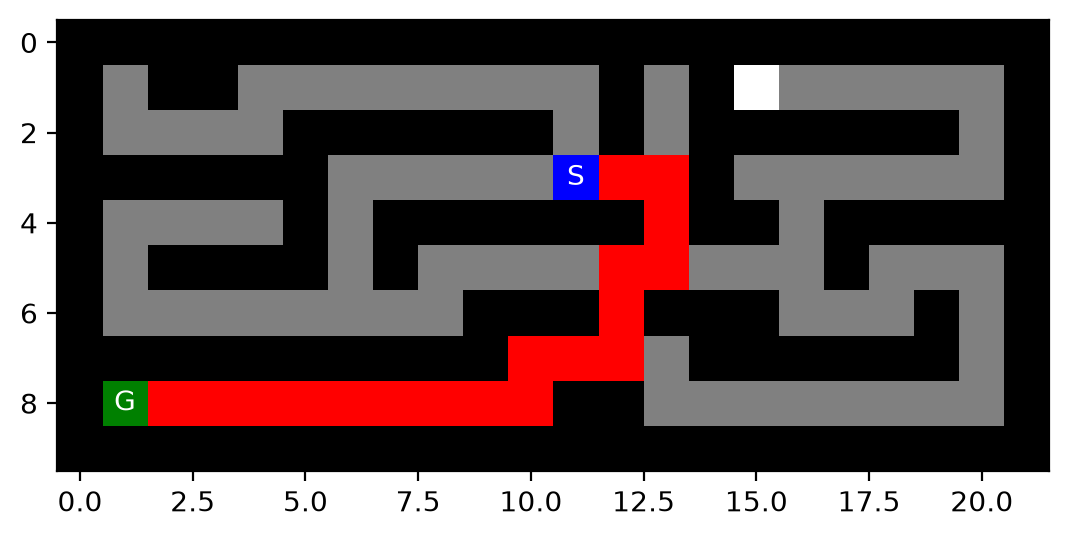

=== BFS Solution on Large Maze ===
Path length (moves): 210
Nodes expanded: 622
Max frontier size: 8
Max nodes in memory: 630
Action sequence (first 30 steps): N -> N -> W -> W -> W -> W -> N -> N -> W -> W -> S -> S -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> N -> N -> E -> E ... [total 210 steps]


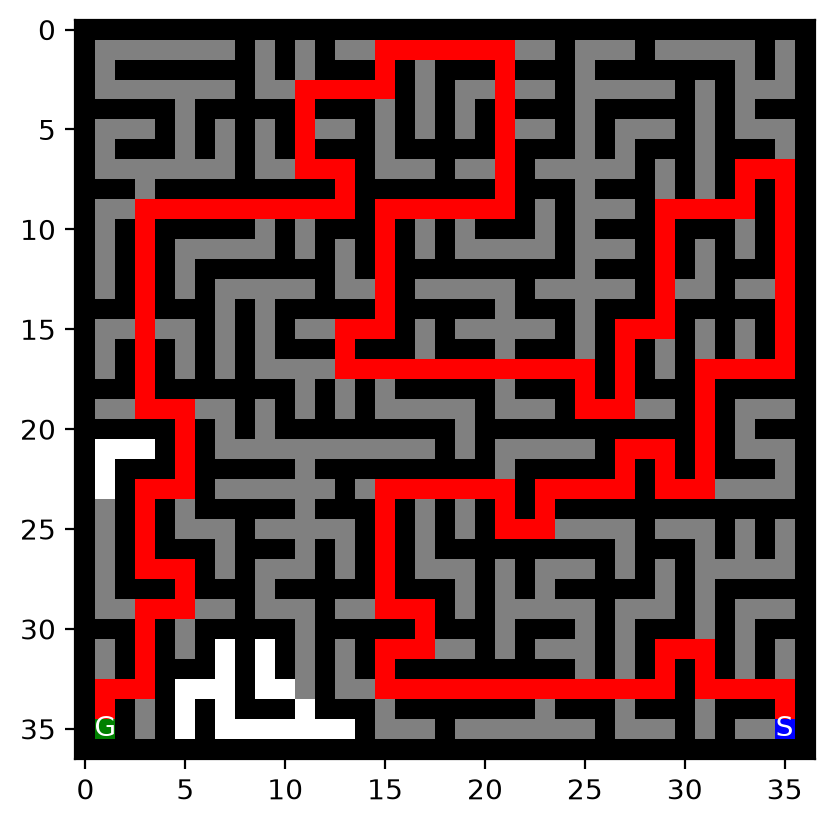

=== BFS Solution on Open Maze ===
Path length (moves): 54
Nodes expanded: 683
Max frontier size: 25
Max nodes in memory: 687
Action sequence: S -> S -> S -> S -> S -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> S -> S -> S -> S -> S -> S -> S -> S -> S -> S -> S -> S -> S -> S -> S -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W -> W


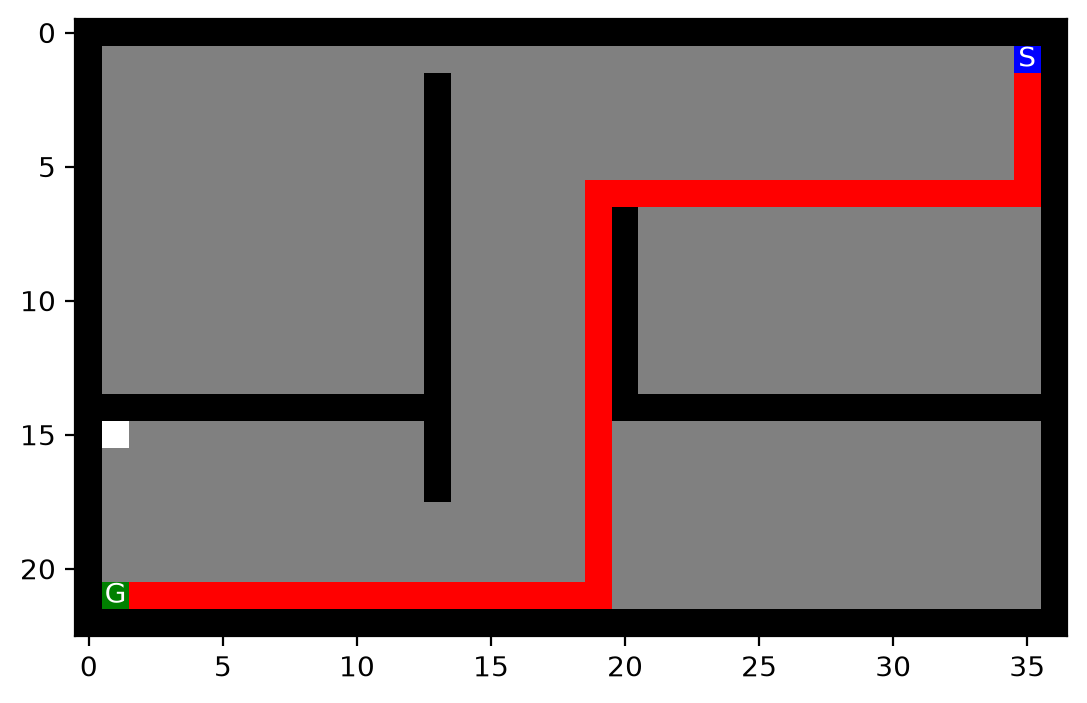

=== BFS Solution on Empty Maze ===
Path length (moves): 14
Nodes expanded: 96
Max frontier size: 12
Max nodes in memory: 101
Action sequence: N -> N -> N -> N -> N -> N -> N -> E -> E -> E -> E -> E -> E -> E


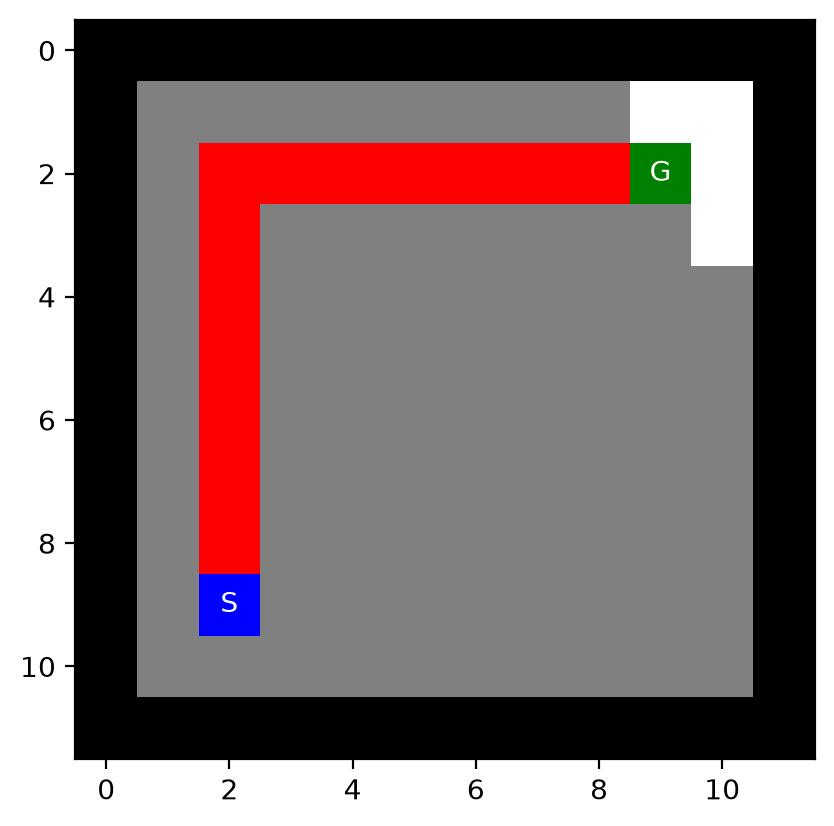


Summary Results:


,maze,path length,# of nodes expanded,max frontier,max memory
0,small,19,93,9,96
1,large,210,622,8,630
2,open,54,683,25,687
3,empty,14,96,12,101


In [12]:
import os
import pandas as pd

maze_files = [
    ('small', 'small_maze.txt'),
    ('large', 'large_maze.txt'),
    ('open', 'open_maze.txt'),
    ('empty', 'empty_maze.txt')
]

bfs_results = []

for label, filename in maze_files:
    if not os.path.exists(filename):
        print(f"File {filename} not found!")
        continue
    
    with open(filename, 'r', encoding='utf-8') as f:
        maze_arr = mh.parse_maze(f.read())
        
    res = bfs_search(maze_arr)
    bfs_results.append({
        'maze': label,
        'path length': res['path_length'],
        '# of nodes expanded': res['expanded_count'],
        'max frontier': res['max_frontier'],
        'max memory': res['max_memory']
    })
    
    display_solution(maze_arr, res, title=f"BFS Solution on {label.capitalize()} Maze")

df_summary = pd.DataFrame(bfs_results)
print("\nSummary Results:")
display(df_summary)


# Task 3: Discussion [3 Points] 

Is your implementation complete and optimal? Explain why. What is the time and space complexity of each of **your** implementation?

### 1. Tính đầy đủ, tính tối ưu và độ phức tạp của BFS

* **Tính đầy đủ (Completeness):**
  **Có, thuật toán BFS được cài đặt đảm bảo tính đầy đủ.**
  * *Giải thích:* Không gian trạng thái mê cung là hữu hạn ($|S| \le \text{rows} \times \text{cols}$). Cài đặt của chúng tôi sử dụng tìm kiếm đồ thị (graph search) với tập hash `reached` để lưu vết tất cả các trạng thái đã ghé thăm, đảm bảo không có ô nào bị đưa vào hàng đợi hay mở rộng quá một lần.
  * BFS mở rộng không gian tìm kiếm theo từng mức độ sâu tăng dần. Do đó, nếu tồn tại đường đi từ $S$ đến $G$, BFS chắc chắn sẽ tìm ra đích và dừng sau hữu hạn bước. Nếu mê cung không có đường đi, tập frontier sẽ rỗng và thuật toán kết thúc báo không tìm thấy nghiệm.

* **Tính tối ưu (Optimality):**
  **Có, thuật toán BFS được cài đặt đảm bảo tính tối ưu.**
  * *Giải thích:* Trong bài toán mê cung này, chi phí cho mọi bước đi đều bằng nhau và bằng 1 ($c = 1$). Khi chi phí mỗi bước đồng nhất, chi phí tích lũy $g(n)$ chính bằng độ sâu của nút trên cây tìm kiếm ($g(n) = \text{depth}(n)$).
  * Do BFS luôn mở rộng các nút theo thứ tự độ sâu không giảm, nút đích đầu tiên được lấy ra khỏi frontier để mở rộng chắc chắn là nút có độ sâu nhỏ nhất, tương ứng với đường đi ngắn nhất ($d$).

* **Độ phức tạp thời gian (Time Complexity):**
  * Trong tìm kiếm theo cây (tree search), độ phức tạp thời gian là $\mathcal{O}(b^d)$, trong đó $b \le 4$ là hệ số phân nhánh và $d$ là độ sâu lời giải tối ưu.
  * Trong tìm kiếm đồ thị trên lưới hữu hạn, mỗi ô đi được $(r, c)$ được đưa vào frontier và mở rộng tối đa một lần, mỗi ô có tối đa 4 liên kết láng giềng. Vì vậy, độ phức tạp thời gian là tuyến tính theo số trạng thái duyệt được:
    $$\mathcal{O}(|V| + |E|) = \mathcal{O}(n)$$
    với $n = |S| \le \text{rows} \times \text{cols}$ và $|E| \le 4n$.

* **Độ phức tạp không gian (Space Complexity):**
  * Trong tìm kiếm theo cây: $\mathcal{O}(b^d)$ để lưu các nút trong frontier.
  * Trong tìm kiếm đồ thị: $\mathcal{O}(n)$ do cần lưu toàn bộ các trạng thái đã gặp trong tập `reached` và các nút ở biên trong hàng đợi `frontier`. Đối với không gian tìm kiếm rộng lớn, dung lượng bộ nhớ lớn này là điểm nghẽn chính của BFS.


How would the planning improve if you use informed search with A* search and the Euclidean distance to the goal as the heuristic? What would the algorithm do differently?

### 2. Cải tiến khi sử dụng tìm kiếm có thông tin (A* với Heuristic khoảng cách Euclidean)

* **Thuật toán A\* hoạt động khác gì so với BFS:**
  * **BFS là tìm kiếm mù (không có thông tin):** Thuật toán mở rộng các nút chỉ dựa trên độ sâu $g(n)$, lan tỏa đồng đều ra mọi hướng theo hình tròn/hình thoi đồng tâm như gợn sóng nước, hoàn toàn không biết hướng nào gần đích hơn.
  * **A\* là tìm kiếm có thông tin (heuristic-guided):** Thuật toán định hướng tìm kiếm thông qua hàm đánh giá:
    $$f(n) = g(n) + h(n)$$
    trong đó $g(n)$ là chi phí thực tế đã đi từ điểm xuất phát đến nút $n$, còn $h(n)$ là ước lượng chi phí còn lại từ nút $n$ đến đích $G$:
    $$h_{\text{Euclidean}}(n) = \sqrt{(r_n - r_{\text{goal}})^2 + (c_n - c_{\text{goal}})^2}$$
  * A* sử dụng hàng đợi ưu tiên theo $f(n)$. Các nút di chuyển theo hướng làm giảm khoảng cách Euclidean tới đích sẽ có giá trị $f(n)$ nhỏ hơn và được ưu tiên lấy ra mở rộng trước, thay vì duyệt dàn trải ra các nhánh đi xa đích.

* **Hiệu quả lập kế hoạch được cải thiện như thế nào:**
  * **Giảm đáng kể số nút mở rộng:** Nhờ có hướng đi rõ ràng hướng thẳng về đích, A* tránh mở rộng phần lớn các vùng không gian đi ngược hướng đích. Ví dụ trong `open_maze` hay `empty_maze`, BFS phải mở rộng lần lượt 683 và 96 nút, trong khi A* tập trung theo một dải hẹp hướng về $G$ và mở rộng ít nút hơn nhiều.
  * **Đảm bảo tính tối ưu (admissibility):** Trên lưới 4 hướng không cho phép đi chéo, khoảng cách đường chim bay Euclidean luôn nhỏ hơn hoặc bằng khoảng cách di chuyển thực tế theo ô lưới (khoảng cách Manhattan):
    $$h_{\text{Euclidean}}(n) \le h_{\text{Manhattan}}(n) \le h^*(n)$$
    Vì $h(n)$ không bao giờ đánh giá quá chi phí thực tế, heuristic Euclidean là **chấp nhận được** (admissible) và **nhất quán** (consistent). Do đó, A* chắc chắn vẫn tìm ra đường đi ngắn nhất tối ưu như BFS, nhưng với chi phí tính toán và số nút mở rộng ít hơn đáng kể.


Your BFS implementation works fine to solve small mazes. Why would it not work for larger problems with millions of states and 100s of actions? What algorithm could be used then?

### 3. Khả năng mở rộng: Vì sao BFS thất bại trên bài toán hàng triệu trạng thái và các giải thuật thay thế

* **Vì sao BFS không thể giải quyết các bài toán lớn ($10^6+$ trạng thái, $100+$ hành động):**
  1. **Bùng nổ bộ nhớ theo hàm mũ:** Độ phức tạp bộ nhớ của BFS là $\mathcal{O}(b^d)$. Giả sử mỗi trạng thái có $b \approx 100$ hành động và độ sâu lời giải là $d = 10$, cây tìm kiếm ở độ sâu 10 sẽ chứa:
     $$b^d = 100^{10} = 10^{20} \text{ nút}$$
     Để lưu trữ $10^{20}$ nút, ngay cả khi mỗi nút chỉ tốn 32 byte, hệ thống cũng cần hơn $3{,}2 \times 10^9$ Terabyte RAM. Trong thực tế, BFS luôn bị tràn bộ nhớ (Out of Memory) rất lâu trước khi cạn kiệt thời gian xử lý của CPU.
  2. **Duyệt mù quáng và lãng phí:** Với hàng triệu trạng thái, việc mở rộng đồng đều ra mọi hướng sẽ khiến thuật toán bị sa lầy vào hàng triệu nhánh vô ích không dẫn tới đích.

* **Các thuật toán có thể sử dụng thay thế:**
  1. **Tìm kiếm sâu dần (Iterative Deepening Search - IDS):**
     * Kết hợp ưu điểm tiết kiệm bộ nhớ của DFS với tính đầy đủ và tối ưu của BFS bằng cách lặp lại DFS với giới hạn độ sâu tăng dần ($l = 0, 1, 2, \dots$).
     * Độ phức tạp bộ nhớ chỉ là **tuyến tính** $\mathcal{O}(b \cdot d)$, loại bỏ hoàn toàn nút thắt tràn RAM của BFS trong khi vẫn đảm bảo tìm ra nghiệm tối ưu cho bài toán chi phí đơn vị.
  2. **Các thuật toán tìm kiếm Heuristic (Informed Search):**
     * **Thuật toán A\*:** Sử dụng heuristic admissible để định hướng, giảm mạnh hệ số phân nhánh hiệu dụng.
     * **IDA\* (Iterative Deepening A\*):** Kết hợp tìm kiếm sâu dần với ngưỡng cắt tỉa theo hàm $f(n)$. Hoạt động với bộ nhớ tuyến tính $\mathcal{O}(b \cdot d)$ mà vẫn đảm bảo nghiệm tối ưu.
     * **SMA\* (Simplified Memory-Bounded A\*) / RBFS (Recursive Best-First Search):** Hoạt động trong một dung lượng bộ nhớ cố định cho trước. Khi đầy bộ nhớ, SMA* sẽ giải phóng các nút có giá trị $f$ kém nhất và chỉ tái tạo lại khi các nhánh khác chứng minh là tồi hơn.
